# ¿Discrimina la policía en el uso de la fuerza?

**Economía Laboral — Clase Práctica 4**


**Fryer, R. G. Jr. (2019)**. *An Empirical Analysis of Racial Differences in Police Use of Force.* Journal of Political Economy 127(3): 1210–1261. 

**Requisitos.** Kernel de R (`IRkernel`) y los paquetes `data.table`, `fixest`, `ggplot2` y `scales`. En la misma carpeta que este notebook tiene que estar `sqf_fryer_2003_2013.Rdata`.

In [26]:
## ------------------------------------------------------------------
## Set-up
## ------------------------------------------------------------------

MUESTRA   <- TRUE      # TRUE = 500 mil detenciones (rápido) | FALSE = base completa
N_MUESTRA <- 500000
SEMILLA   <- 20260821

## install.packages(c("data.table", "fixest", "ggplot2", "scales"))
suppressPackageStartupMessages({
  library(data.table)
  library(fixest)
  library(ggplot2)
  library(scales)
})
setFixest_notes(FALSE)

## paleta y tema
AZUL <- "#325585"; ROJO <- "#A31F34"; GRIS <- "#7d8590"; VERDE <- "#2f6b4f"
theme_set(
  theme_minimal(base_size = 12) +
    theme(panel.grid.minor   = element_blank(),
          panel.grid.major.x = element_blank(),
          plot.title    = element_text(face = "bold", colour = AZUL, size = 13),
          plot.subtitle = element_text(colour = GRIS, size = 10),
          plot.caption  = element_text(colour = GRIS, size = 8.5, hjust = 0),
          legend.position = "top", legend.title = element_blank(),
          strip.text = element_text(face = "bold", colour = AZUL, size = 9.5))
)
options(repr.plot.width = 9, repr.plot.height = 5, repr.plot.res = 140)

fmt <- function(x) format(round(x), big.mark = ".", decimal.mark = ",")

Warning message:
"package 'data.table' was built under R version 4.4.3"
Warning message:
"package 'fixest' was built under R version 4.4.3"
Warning message:
"package 'ggplot2' was built under R version 4.4.3"
Warning message:
"package 'scales' was built under R version 4.4.3"


---

# Parte 1 · Contexto

Roland Fryer es economista de Harvard y fue el primer afroamericano en ganar la John Bates Clark Medal. En este trabajo, buscó estimar el efecto del racismo en la violencia de los encuentros policiales.

Las bases de datos:

1. **Stop, Question and Frisk (SQF)** de Nueva York: 5 millones de detenciones peatonales entre 2003 y 2013, con siete niveles de fuerza registrados por el policía.
2. **Police-Public Contact Survey**: encuesta nacional, perspectiva del civil.
3. **Tiroteos policiales** en 16 jurisdicciones, codificados a mano a partir de los relatos de los incidentes.
4. **Arrestos de Houston** en categorías donde la fuerza letal podría estar justificada; un equipo leyó los expedientes y codificó ~290 variables por caso, a 30–45 minutos por expediente.

Los resultados que publica son dos, y apuntan en direcciones opuestas:

- En **fuerza no letal**, los civiles negros e hispanos tienen más de 50% más de probabilidad de sufrir algún uso de fuerza. Con 125 variables de control el odds ratio baja a 1,18 pero no desaparece.
- En **tiroteos policiales** no encuentra ninguna diferencia racial. Ni en los datos crudos ni con controles. De hecho el punto estimado va en la dirección contraria. Los civiles negros son 23,5% menos propensos a recibir un disparo.

Ese segundo resultado hizo que el paper apareciera en muchísimos medios.

---

# Parte 2 · ¿Cuál es el efecto causal de la raza?

## 2.1 En resultados potenciales

Retomemos exactamente la notación de la Clase 3. Sea

$$D_i = \begin{cases} 1 & \text{el civil } i \text{ `es' negro} \\ 0 & \text{el civil } i \text{ `es' blanco} \end{cases}$$

Cada encuentro tiene dos resultados potenciales, $Y_{1i}$ e $Y_{0i}$, y observamos uno solo:

$$Y_i = Y_{1i} D_i + Y_{0i}(1 - D_i)$$

La diferencia simple de medias (SDO) se descompone como siempre:

$$\underbrace{\mathbb{E}[Y_i \mid D_i=1] - \mathbb{E}[Y_i \mid D_i=0]}_{SDO}
= \underbrace{\mathbb{E}[Y_{1i} - Y_{0i} \mid D_i = 1]}_{\alpha_{ATT}}
+ \underbrace{\mathbb{E}[Y_{0i} \mid D_i=1] - \mathbb{E}[Y_{0i} \mid D_i=0]}_{\text{sesgo de selección}}$$

## 2.2 ¿Qué significa $Y_{0i}$ acá?

$D_i$ es la raza del civil, no se puede asignar aleatoriamente.

Entonces, ¿qué es $Y_{0i}$ para un civil negro? Es el uso de fuerza que ese mismo encuentro habría tenido si el policía hubiera visto a un civil blanco: mismo lugar, misma hora, misma conducta, mismo policía.

## 2.3 El supuesto de identificación

Como no hay aleatorización, la única salida es el supuesto de la Clase 3: **independencia condicional** o **selección en observables**.

$$\mathbb{E}[Y_{0i} \mid D_i = 1, X_i] = \mathbb{E}[Y_{0i} \mid D_i = 0, X_i]$$

Bajo IC, la comparación dentro de celdas definidas por $X_i$ tiene interpretación causal:

$$\underbrace{\mathbb{E}[Y_i \mid X_i = x, D_i=1] - \mathbb{E}[Y_i \mid X_i = x, D_i=0]}_{\text{observable}}
= \underbrace{\mathbb{E}[Y_{1i} - Y_{0i} \mid X_i = x, D_i = 1]}_{\rho_x}$$

y si suponemos efecto constante $\rho_x = \rho$, pasamos del emparejamiento a la regresión:

$$Y_i = \alpha + \rho\,D_i + \gamma' X_i + e_i$$

**El core de nuestra tarea: ¿Qué tiene que haber adentro de $X_i$?**

El DAG del problema, entonces, es éste:

$$
\begin{array}{ccccc}
 & & X & & \\[6pt]
 & \swarrow & & \searrow & \\[6pt]
D & & \longrightarrow & & Y
\end{array}
$$

| | |
|---|---|
| $D$ | raza del civil |
| $Y$ | uso de fuerza |
| $X$ | contexto y conducta: precinto, hora, zona conflictiva, movimientos furtivos, uniforme |

---

# Parte 3 · La estrategia

## 3.1 Dale y Krueger (2002)

| | (1) | (2) | (3) | (4) | (5) | (6) |
|---|---|---|---|---|---|---|
| | *sin controles de selección* | | | *con controles de selección* | | |
| **Escuela privada** | .135 | .095 | .086 | **.007** | **.003** | **.013** |
| | (.055) | (.052) | (.034) | (.038) | (.039) | (.025) |
| SAT propio /100 | | .048 | .016 | | .033 | .001 |
| log ingreso parental | | | .219 | | | .190 |

## 3.2 El sesgo de variables omitidas

Si la regresión "larga" es

$$Y_i = \alpha^l + \rho D_i + \gamma A_i + e_i$$

y corremos la "corta" omitiendo $A_i$,

$$Y_i = \alpha^c + \rho^c D_i + u_i \qquad\Longrightarrow\qquad
\rho^c = \rho + \gamma\,\delta_{AD}$$

$$\rho^c - \rho = \underbrace{\gamma\ \times \delta_{AD}}_{OVB}$$

donde $\delta_{AD}$ es el coeficiente de regresar $A_i$ sobre $D_i$. El sesgo tiene dos piezas: **cuánto importa lo omitido** ($\gamma$) por **cuánto se correlaciona con el tratamiento** ($\delta_{AD}$).

---

En Dale y Krueger todos los controles son anteriores al tratamiento. Ninguno es consecuencia de haber ido a la privada.


---

# Parte 4 · Los datos

Stop, Question and Frisk. Entre 2003 y 2013 quedaron registradas casi 5 millones de detenciones.

Fryer los ordena de menor a mayor intensidad, y construye la variable como "al menos" este nivel:

| nivel | fuerza |
|---|---|
| 1 | poner las manos encima |
| 2 | empujar contra una pared |
| 3 | esposar |
| 4 | desenfundar el arma |
| 5 | tirar al suelo |
| 6 | apuntar con el arma |
| 7 | gas pimienta o bastón |

El archivo `sqf_fryer_2003_2013.Rdata` es la base ya limpia por Knox, Lowe y Mummolo a partir de los archivos públicos de la NYPD.

In [28]:
## ------------------------------------------------------------------
## Carga y armado de la base
## ------------------------------------------------------------------

load("sqf_fryer_2003_2013.Rdata")
sqf <- as.data.table(d2); rm(d2)

razas_abbr <- c("white", "black", "hisp", "asian", "other")
razas      <- c("blanco", "negro", "hispano", "asiatico", "otro")
sqf[, raza := factor(as.character(race2), levels = razas_abbr, labels = razas)]

## los 19 controles de la especificación principal de Fryer
CONTROLES <- c("gender", "age2", "daytime", "inout2", "ac_incid", "ac_time",
               "offunif2", "typeofid2", "othpers2", "cs_objcs", "cs_descr",
               "cs_casng", "cs_lkout", "cs_cloth", "cs_drgtr", "cs_furtv",
               "cs_vcrim", "cs_bulge", "cs_other")

sqf <- sqf[, c("force", "raza", CONTROLES, "pct", "year"), with = FALSE]

sqf <- na.omit(sqf)

sqf[, `:=`(pct       = factor(pct),
           year      = factor(year),
           typeofid2 = factor(typeofid2),
           edad      = age2,
           edad2     = age2^2,
           y         = as.integer(force >= 1))]   # al menos las manos

cat("Detenciones con datos completos:", fmt(nrow(sqf)), "\n")
cat("N de la Tabla 2A de Fryer      :", fmt(4927962),
    " (él conserva los incompletos con dummies de faltante)\n\n")

set.seed(SEMILLA)
if (MUESTRA) sqf <- sqf[sample(.N, min(N_MUESTRA, .N))]

Detenciones con datos completos: 4.132.257 
N de la Tabla 2A de Fryer      : 4.927.962  (él conserva los incompletos con dummies de faltante)



In [30]:
## ----------------------------------------------------------
## ¿A quién detiene la policía, y a quién le aplica fuerza?
## ----------------------------------------------------------

desc <- sqf[, .(detenciones = .N,
                `% de las detenciones` = round(100 * .N / nrow(sqf), 2),
                `% con uso de fuerza`  = round(100 * mean(y), 2)),
            by = raza][order(-detenciones)]
print(desc)

cat("\nDistribución del nivel máximo de fuerza registrado:\n")
print(sqf[, .(casos = .N, `%` = round(100*.N/nrow(sqf), 2)), by = force][order(force)])

       raza detenciones % de las detenciones % con uso de fuerza
     <fctr>       <int>                <num>               <num>
1:    negro      298229                59.65               22.36
2:  hispano      123174                24.63               22.64
3:   blanco       49680                 9.94               16.27
4: asiatico       15357                 3.07               16.46
5:     otro       13560                 2.71               19.31

Distribución del nivel máximo de fuerza registrado:
   force  casos     %
   <num>  <int> <num>
1:     0 392201 78.44
2:     1  74231 14.85
3:     2  12261  2.45
4:     3  15689  3.14
5:     4    663  0.13
6:     5   3090  0.62
7:     6   1696  0.34
8:     7    169  0.03


---

# Parte 5 · El movimiento de los coeficientes

Fryer estima una regresión logística (logit):

$$\ln\!\left(\frac{\Pr(\text{Fuerza}_{ipt} = 1)}{1 - \Pr(\text{Fuerza}_{ipt} = 1)}\right)
= \text{Raza}_i'\,\alpha + X_{it}'\,\beta + Z_{pt}'\,\mu + \nu_t + \omega_p + \varepsilon_{ipt}$$

donde $i$ indexa al civil, $p$ al precinto y $t$ al tiempo. Los coeficientes se reportan como **odds ratios** respecto de los civiles blancos, con errores estándar clusterizados por precinto.

| fila | controles |
|---|---|
| a | nada |
| b | + demografía del civil (sexo, edad, edad²) |
| c | + características del encuentro (adentro/afuera, día/noche, zona conflictiva, uniforme, tipo de identificación, si había otros) |
| d | + conducta del civil (los diez indicadores `cs_*`: movimientos furtivos, bulto sospechoso, vestimenta, coincide con una descripción, ...) |
| e | + efectos fijos de precinto y de año |

In [34]:
## ------------------------------------------------------------------
## Tabla 2, panel A
## ------------------------------------------------------------------

X_demo     <- "gender + edad + edad2"
X_encuentro<- "daytime + inout2 + ac_incid*ac_time + offunif2 + typeofid2 + othpers2"
X_conducta <- paste("cs_objcs + cs_descr + cs_casng + cs_lkout + cs_cloth +",
                    "cs_drgtr + cs_furtv + cs_vcrim + cs_bulge + cs_other")

escalera <- list(
  "a. sin controles"        = list(x = "raza", fe = NULL),
  "b. + demografía"         = list(x = paste("raza", X_demo, sep = " + "), fe = NULL),
  "c. + encuentro"          = list(x = paste("raza", X_demo, X_encuentro, sep = " + "), fe = NULL),
  "d. + conducta"           = list(x = paste("raza", X_demo, X_encuentro, X_conducta, sep = " + "), fe = NULL),
  "e. + EF precinto y año"  = list(x = paste("raza", X_demo, X_encuentro, X_conducta, sep = " + "),
                                   fe = "pct + year")
)

estimar <- function(spec, datos = sqf, dep = "y"){
  f <- as.formula(paste(dep, "~", spec$x,
                        if (!is.null(spec$fe)) paste("|", spec$fe) else ""))
  m <- feglm(f, data = datos, family = binomial("logit"), cluster = ~pct)
  ct <- as.data.frame(coeftable(m)); ct$term <- rownames(ct)
  ct <- ct[ct$term %in% c("razanegro", "razahispano"), ]
  data.table(raza = sub("^raza", "", ct$term),
             or   = exp(ct$Estimate),
             se   = exp(ct$Estimate) * ct$`Std. Error`,   # delta method
             lo   = exp(ct$Estimate - 1.96 * ct$`Std. Error`),
             hi   = exp(ct$Estimate + 1.96 * ct$`Std. Error`))
}
t0 <- Sys.time()
tabla2 <- rbindlist(lapply(names(escalera),
                           function(nm) cbind(esp = nm, estimar(escalera[[nm]]))))
cat("tiempo:", round(difftime(Sys.time(), t0, units = "secs")), "segundos\n\n")

## media blanca (columna 1 de la tabla de Fryer)
cat("Media blancos:", round(sqf[raza == "blanco", mean(y)], 3), "\n")
cat("Fryer                : 0.153\n\n")

print(dcast(tabla2, esp ~ raza, value.var = c("or", "se"))[
  , .(esp, negro = sprintf("%.3f (%.3f)", or_negro, se_negro),
          hispano = sprintf("%.3f (%.3f)", or_hispano, se_hispano))])

tiempo: 8 segundos

Media blancos: 0.163 
Fryer                : 0.153

Key: <esp>
                      esp         negro       hispano
                   <char>        <char>        <char>
1:       a. sin controles 1.482 (0.142) 1.506 (0.133)
2:        b. + demografía 1.433 (0.143) 1.450 (0.132)
3:         c. + encuentro 1.611 (0.151) 1.576 (0.142)
4:          d. + conducta 1.435 (0.126) 1.471 (0.124)
5: e. + EF precinto y año 1.161 (0.034) 1.107 (0.028)


In [37]:
## ------------------------------------------------------------------
## Checkeo contra los números publicados
## ------------------------------------------------------------------
# ctrl+f 1.534

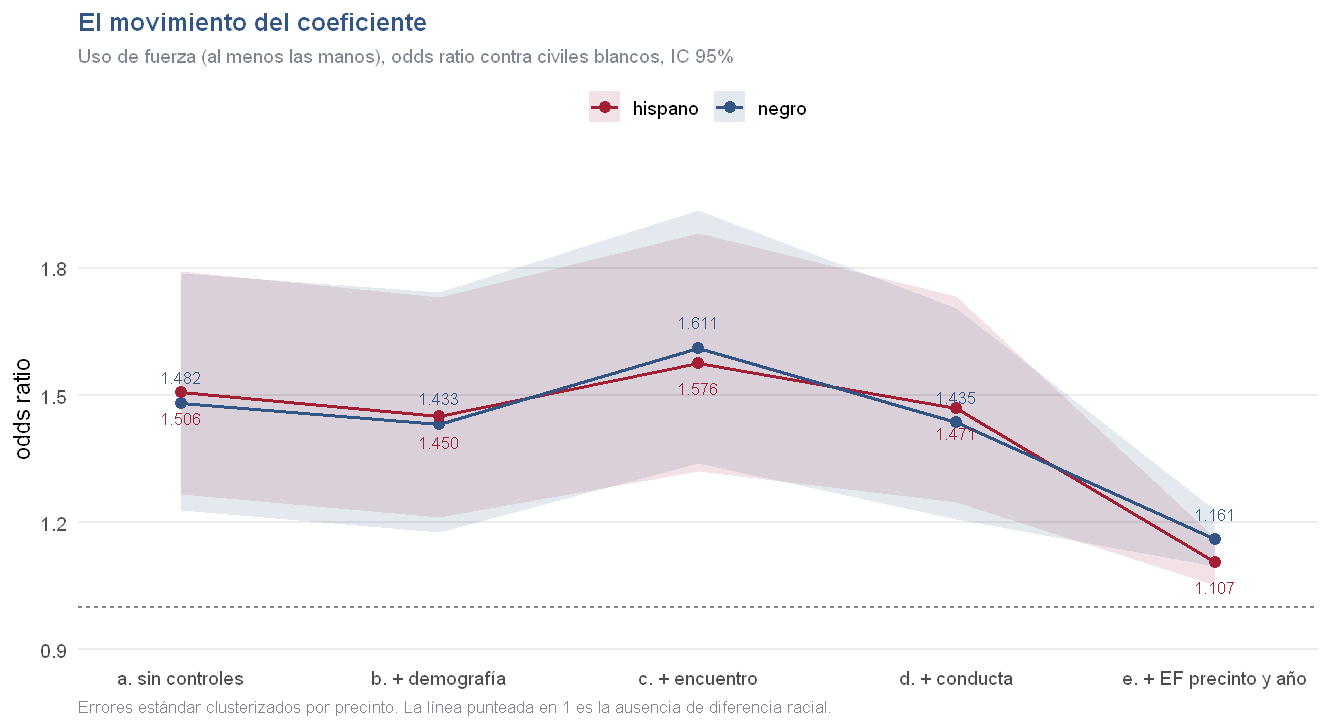

In [36]:
## --------------------------------------
## Grafico
## --------------------------------------

tabla2[, k := as.integer(factor(esp, levels = names(escalera)))]
options(repr.plot.width = 9.5, repr.plot.height = 5.2)

ggplot(tabla2, aes(k, or, colour = raza, fill = raza, group = raza)) +
  geom_hline(yintercept = 1, linetype = "22", colour = GRIS) +
  geom_ribbon(aes(ymin = lo, ymax = hi), alpha = .13, colour = NA) +
  geom_line(linewidth = .8) +
  geom_point(size = 2.6) +
  geom_text(aes(label = sprintf("%.3f", or),
                vjust = ifelse(raza == "negro", -1.5, 2.4)),
            size = 3.1, show.legend = FALSE) +
  scale_x_continuous(breaks = 1:5, labels = names(escalera),
                     expand = expansion(mult = .10)) +
  scale_y_continuous(expand = expansion(mult = .13)) +
  scale_colour_manual(values = c(negro = AZUL, hispano = ROJO)) +
  scale_fill_manual(values   = c(negro = AZUL, hispano = ROJO)) +
  labs(title = "El movimiento del coeficiente",
       subtitle = "Uso de fuerza (al menos las manos), odds ratio contra civiles blancos, IC 95%",
       x = NULL, y = "odds ratio",
       caption = "Errores estándar clusterizados por precinto. La línea punteada en 1 es la ausencia de diferencia racial.")

## 5.1 Lectura del OVB

**+ Controles demograficos.** Agregar sexo y edad casi no mueve nada, la composición demográfica de los detenidos no parece explicar la brecha.

**+ Controles de encuentro.** El coeficiente sube. Es importnate entender la intuición del sesgo acá. Negros y blancos no se distribuyen igual por tipo de encuentro. El hecho de que el coeficiente suba cuando controlamos por circunstancias, sugiere que los negros se los encuentra más frecuentemente en contextos que tienen menor violencia en promedio. Pero, mantiendo las características de la situación constante, los negros parecen recibir más violencia. Ojo acá porque acá podría haber un sesgo que vimos en la clase 2.

**+ Controles de conducta.** no cambia mucho...

**+ Controles del precinto.** Acá sí hay un salto. Esto es análago a los grupos de selectividad de Dale y Krueger. Esto sugiere que los negros están en barrios que reciben más violencia policial en promedio. Si comparamos blancos y negros dentro de un mismo barrio, la diferencia en la violencia que reciben no es tan grande.

Fryer sigue intentando con otras variables y el coeficiente no se mueve mucho.

tiempo: 38 segundos


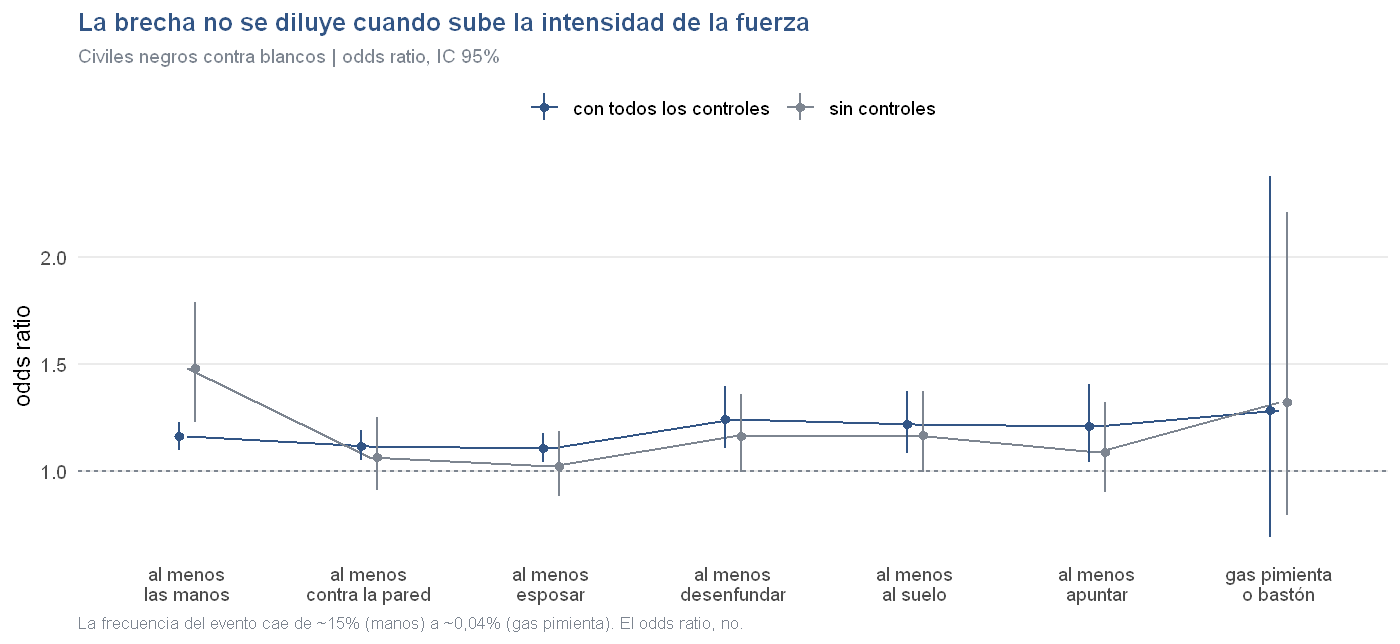

In [45]:
## ------------------------------------------------------------------
## Figura 1
## ------------------------------------------------------------------

niveles <- c("al menos\nlas manos", "al menos\ncontra la pared", "al menos\nesposar",
             "al menos\ndesenfundar", "al menos\nal suelo", "al menos\napuntar",
             "gas pimienta\no bastón")

X_TODO <- paste(X_demo, X_encuentro, X_conducta, sep = " + ")

or_umbral <- function(k, con_controles){
  dd <- copy(sqf)[, yk := as.integer(force >= k)]
  spec <- if (con_controles) list(x = paste("raza", X_TODO, sep = " + "), fe = "pct + year")
          else               list(x = "raza", fe = NULL)
  cbind(k = k, nivel = niveles[k],
        modelo = if (con_controles) "con todos los controles" else "sin controles",
        estimar(spec, datos = dd, dep = "yk"))
}

t0 <- Sys.time()
fig1 <- rbindlist(lapply(1:7, function(k) rbind(or_umbral(k, FALSE), or_umbral(k, TRUE))))
cat("tiempo:", round(difftime(Sys.time(), t0, units = "secs")), "segundos\n")

fig1[, nivel := factor(nivel, levels = niveles)]
options(repr.plot.width = 10, repr.plot.height = 4.6)

ggplot(fig1[raza == "negro"], aes(nivel, or, colour = modelo, group = modelo)) +
  geom_hline(yintercept = 1, linetype = "22", colour = GRIS) +
  geom_line(linewidth = .7) +
  geom_pointrange(aes(ymin = lo, ymax = hi), size = .35,
                  position = position_dodge(width = .18)) +
  scale_colour_manual(values = c("sin controles" = GRIS,
                                 "con todos los controles" = AZUL)) +
  labs(title = "La brecha no se diluye cuando sube la intensidad de la fuerza",
       subtitle = "Civiles negros contra blancos | odds ratio, IC 95%",
       x = NULL, y = "odds ratio",
       caption = "La frecuencia del evento cae de ~15% (manos) a ~0,04% (gas pimienta). El odds ratio, no.")

In [47]:
print(fig1[raza == "negro" & modelo == "con todos los controles",
           .(nivel, or = round(or,3), lo = round(lo,3), hi = round(hi,3))])
#fryer logra significancia en todos los niveles de violencia.

                       nivel    or    lo    hi
                      <fctr> <num> <num> <num>
1:       al menos\nlas manos 1.161 1.096 1.229
2: al menos\ncontra la pared 1.117 1.050 1.189
3:         al menos\nesposar 1.107 1.041 1.177
4:     al menos\ndesenfundar 1.243 1.108 1.394
5:        al menos\nal suelo 1.218 1.082 1.372
6:         al menos\napuntar 1.208 1.039 1.405
7:    gas pimienta\no bastón 1.282 0.692 2.376


## 5.2 Lo más destacado del paper

Con los datos de tiroteos policiales de Houston (no se consiguen para replicar) Fryer estima el mismo tipo de modelo y encuentra,

| | odds ratio (negros vs. no negros) |
|---|---|
| sin controles | 0,765 |
| + demografía del sospechoso | 0,786 |
| + demografía del policía | 0,780 |
| + características del encuentro | 0,890 |
| + arma del sospechoso | 0,806 |
| + año | 0,726 |

*"Blacks are 23.5 percent less likely to be shot by police, relative to whites, in an interaction."*

# Parte 6 · Mal control

Cada fila de esta base es una **detención**. Para que un encuentro entre un policía y un civil aparezca acá, el policía tuvo que decir detener al civil.

Llamemos $M_i$ a esa decisión:

$$M_i = \begin{cases} 1 & \text{el policía detiene al civil } i \\ 0 & \text{no lo detiene} \end{cases}$$

Toda la base es el subconjunto $M_i = 1$.

$$
\begin{array}{ccccc}
D & \longrightarrow & \boxed{\;M\;} & \longrightarrow & Y \\[6pt]
 & \searrow & & \nearrow & \\[6pt]
 & & \longrightarrow & &
\end{array}
$$

## 6.1 El problema con condicionar en la detención

**Es un mediador.** Si la raza afecta la probabilidad de ser detenido, parte del efecto total de la raza sobre la fuerza policial *pasa por* $M$. Al condicionar en $M = 1$ bloqueamos ese canal. Es el mismo problema que controlar por ocupación en una regresión de salarios contra escolaridad.

**Es un collider.** Consideremos lo que el policía ve y nosotros no: *"unobservable subjective aspects of the encounter, such as an officer's suspicion or sense of threat."* (KLM, 2020). Llamemos a eso $U_i$.

$U$ afecta la decisión de detener y el uso de fuerza.

$$
\begin{array}{ccccc}
 & & U & & \\[6pt]
 & & \downarrow & \searrow & \\[6pt]
D & \longrightarrow & \boxed{\;M\;} & \longrightarrow & Y \\[6pt]
 & \searrow & & \nearrow & \\[6pt]
 & & \longrightarrow & &
\end{array}
$$

El camino que nos va a abrir una relación espuria:

$$D \longrightarrow M \longleftarrow U$$

$$\textcolor{red}{D \;\dashleftarrow\!\!\dashrightarrow\; U} \;\longrightarrow\; Y$$

La flecha punteada roja no es causal!!!

## 6.2 Preguntas

- ¿Hacia donde se sesga el coeficiente de Fryer al controlar por detenciones?
- ¿Cómo lo podemos reinterpretar?
- ¿Cómo se puede arreglar esto?

---

# Parte 7 · Simulación

La ventaja de simular es que conocemos la respuesta.

- Hay discriminación real en el uso de la fuerza: $\tau = +0{,}10$. Ante el mismo encuentro, un civil negro tiene 10 puntos porcentuales más de probabilidad de recibir fuerza.
- Hay discriminación en la decisión de detener: el policía tiene un umbral más bajo para los negros.
- Observamos el contexto $X$ y podmeos controlar por él.
- No observamos $U$, la amenaza percibida.
- No hay fuerza sin detención: $Y = 0$ si $M = 0$.

Con la base completa (todos los encuentros) recuperaríamos $\tau$. Pero sólo vemos las filas con $M = 1$.

In [60]:
simular <- function(n = 300000, tau = 0.10, gamma = 0, umbral = 1.2, semilla = NULL){
  if (!is.null(semilla)) set.seed(semilla)
  D <- rbinom(n, 1, .5)                                    # 1 = negro
  X <- rbinom(n, 1, .4)                                    # contexto observado
  U <- rnorm(n)                                            # amenaza percibida, no observada
  M <- as.integer(U + gamma * D + 0.5 * X > umbral)        # decisión de detener
  pY <- pmin(pmax(0.05 + tau * D + 0.2 * U + 0.10 * X, 0), 1)
  Y  <- M * rbinom(n, 1, pY)                               # sin detención no hay fuerza
  data.table(D, X, U, M, Y)
}

s <- simular(semilla = SEMILLA)

cat("Encuentros simulados :", fmt(nrow(s)), "\n")
cat("Terminan en detención:", fmt(sum(s$M)),
    sprintf("(%.1f%%)\n\n", 100 * mean(s$M)))
cat(sprintf("Tasa de detención. negros: %.3f   blancos: %.3f\n",
            s[D == 1, mean(M)], s[D == 0, mean(M)]))
cat(sprintf("Amenaza percibida promedio entre los detenidos. negros: %.2f   blancos: %.2f\n",
            s[M == 1 & D == 1, mean(U)], s[M == 1 & D == 0, mean(U)]))

Encuentros simulados : 3e+05 
Terminan en detención: 50.083 (16.7%)

Tasa de detención. negros: 0.167   blancos: 0.167
Amenaza percibida promedio entre los detenidos. negros: 1.45   blancos: 1.46


In [62]:
## ------------------------------------------------------------------
## Lo que observamos
## ------------------------------------------------------------------

det <- s[M == 1]

cat(sprintf("Efecto VERDADERO (τ)                                    : %+.4f\n", 0.10), "\n")
cat(sprintf("Estimador ingenuo, controlando por todo lo observable: %+.4f\n",
            coef(lm(Y ~ D + X, det))[["D"]]))
cat(sprintf("Controlando por X y por U: %+.4f\n",
            coef(lm(Y ~ D + X + U, det))[["D"]]))

Efecto VERDADERO (τ)                                    : +0.1000
 
Estimador ingenuo, controlando por todo lo observable: +0.0956
Controlando por X y por U: +0.0971


---

## Preguntas finales

1. En la Parte 5 el coeficiente sube al agregar características del encuentro (1,44 → 1,62). Usando la fórmula de OVB, $\rho^c = \rho + \gamma\,\delta_{AD}$, ¿qué signos tienen que tener $\gamma$ y $\delta_{AD}$ para que pase eso? Discuta una historia coherente con eso.

2. Los efectos fijos de precinto son el control que más mueve el coeficiente. ¿Son buenos controles o son malos controles? ¿Cambia tu respuesta si la policía asignara patrullas según la composición racial del barrio?

3. Los diez indicadores de conducta civil (movimientos furtivos, bulto sospechoso, vestimenta) los completa el mismo policía que decidió usar la fuerza, después del hecho. Repasá la discusión de control por proxy de la Clase 3, y comentá en qué se parece y en qué se diferencia.

4. Volvamos al resultado de los tiroteos. Fryer lo interpreta como evidencia de costos convexos: discriminar es barato abajo de la escalera de violencia y carísimo arriba. Después de la Parte 7, ¿cuál es la interpretación alternativa? ¿Cómo distinguirías empíricamente entre las dos?

### Referencias

- Dale, S. y Krueger, A. (2002). "Estimating the Payoff to Attending a More Selective College." *QJE* 117(4): 1491–1527.
- Fryer, R. G. Jr. (2019). "An Empirical Analysis of Racial Differences in Police Use of Force." *JPE* 127(3): 1210–1261.